# Week 4 — a reception desk and a picture puzzle

The API is a reception desk for TIFF uploads. Tiling cuts a bigger picture into model-sized squares and puts the answers back. The timeline is an explicitly simulated display because our dataset has no verified observation dates. We reuse the saved Week 3 model without retraining.

## 1. Open the project
Select the project `.venv` kernel in VS Code. The saved demonstration reports and chart are small and included in GitHub. Creating a fresh artificial mosaic requires the locally prepared dataset.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if ROOT.name == "notebooks": ROOT = ROOT.parent
sys.path.insert(0,str(ROOT / "src"))
report = json.loads((ROOT / "reports/week4/tiling_demo.json").read_text())
print(report["demonstration"])
print("Output shape (bands, height, width):", report["output_shape_bhw"])

Artificial 130×97 mosaic; not a real satellite or temporal scene
Output shape (bands, height, width): [4, 97, 130]


## 2. Cut the puzzle into squares
Our model needs 64×64 pixels. A 130×97 image needs three columns and two rows of windows. The last column is only two pixels wide, and the last row is 33 pixels high. Window offsets are pixel coordinates, not GPS coordinates.

In [2]:
from terraspectra.tiling import windows
for window in windows(130,97):
    print("Column", int(window.col_off), "row", int(window.row_off),
          "width", int(window.width), "height", int(window.height))

Column 0 row 0 width 64 height 64
Column 64 row 0 width 64 height 64
Column 128 row 0 width 2 height 64
Column 0 row 64 width 64 height 33
Column 64 row 64 width 64 height 33
Column 128 row 64 width 2 height 33


## 3. What happens to tiny edge squares?
We repeat their last row/column until the model gets a full 64×64 input. This keeps the input shape consistent but may affect classification. After predicting, we write only the original real width/height; padding never enlarges the output raster. The edge policy is an engineering demonstration, not evidence of accurate edge predictions.

In [3]:
small = np.array([[1,2],[3,4]])
padded = np.pad(small, ((0,2),(0,2)), mode="edge")
print("Tiny illustration, before padding:")
print(small)
print("After repeating edges:")
print(padded)

Tiny illustration, before padding:
[[1 2]
 [3 4]]
After repeating edges:
[[1 2 2 2]
 [3 4 4 4]
 [3 4 4 4]
 [3 4 4 4]]


## 4. Classify and put back
Each real tile goes through the saved scaler, PCA, pooling and CNN + transformer. We get three scores and a class ID. We repeat those four numbers over the tile pixels and write the window directly to disk. This produces a block map, not a disease mask learned at pixel level.

Output band order: ['Health', 'Other', 'Rust', 'class_id']
(0, 0) Health padded: False
(0, 64) Other padded: False
(0, 128) Health padded: True
(64, 0) Other padded: True
(64, 64) Health padded: True
(64, 128) Other padded: True


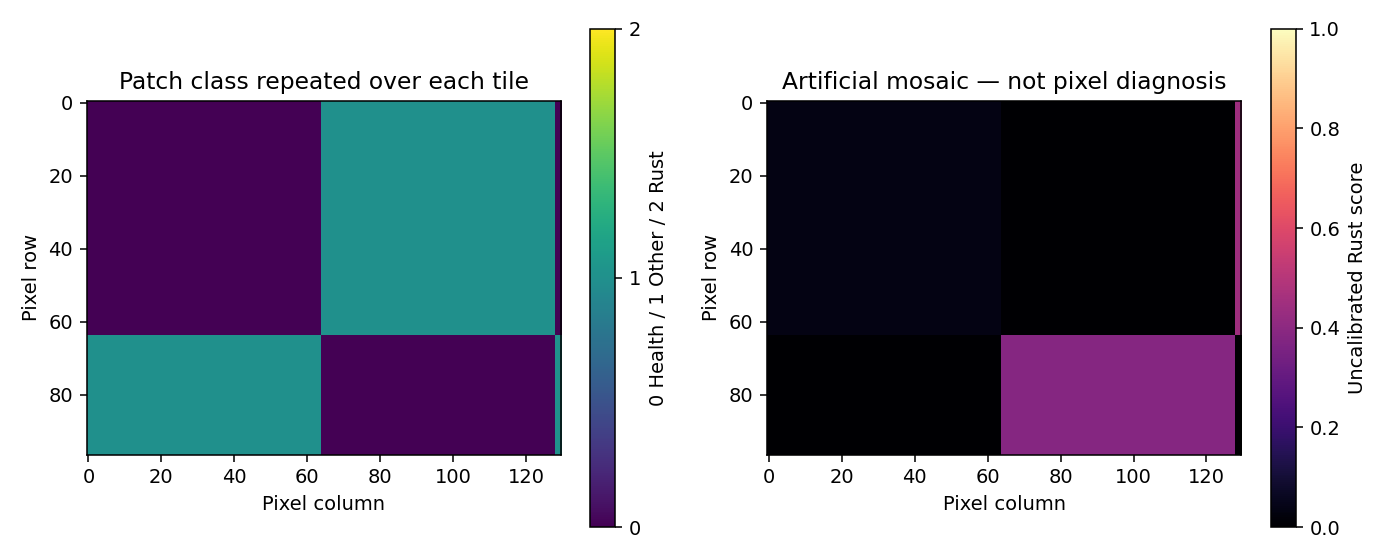

In [4]:
print("Output band order:", report["band_order"])
for tile in report["tiles"]:
    print((tile["row"],tile["column"]),tile["predicted_class"], "padded:",tile["edge_padded"])
from IPython.display import display, Image
display(Image(filename=str(ROOT / "reports/week4/tiling_demo.png")))

The demonstration arranged real training patches into an artificial scene. Its coordinates are invented and explicitly tagged. The image above is a computational example, not a satellite acquisition or a model accuracy evaluation.

## 5. Run a small real tiling example
This cell uses temporary files and removes them when finished. It reads the local Week 1 data if available. The model loads once and is reused for all six windows. This is small enough for the laptop; it is not a giant-raster benchmark.

In [5]:
import tempfile
import rasterio
from terraspectra.week4_demo import make_mosaic
from terraspectra.tiling import TilePredictor, classify_raster
if (ROOT / "data/raw/train").exists():
    with tempfile.TemporaryDirectory(prefix="terraspectra-notebook-") as temp:
        source, output = Path(temp)/"artificial.tif", Path(temp)/"scores.tif"
        make_mosaic(source)
        fresh = classify_raster(source,output,TilePredictor())
        with rasterio.open(output) as image:
            print("Output dimensions:", image.width, image.height, "bands:",image.count)
            print("Copied synthetic CRS:",image.crs)
        print("Tiles processed:",fresh["tile_count"])
else:
    print("Prepare Week 1 data to run this optional local example. Saved reports remain available.")

Output dimensions: 130 97 bands: 4
Copied synthetic CRS: EPSG:4326
Tiles processed: 6


## 6. Talk to the API
Start it in a VS Code terminal with:

```bash
PYTHONPATH=src python -m uvicorn terraspectra.api:app --host 127.0.0.1 --port 8000 --workers 1
```

`/api/predict` accepts one 64×64 patch and returns JSON. `/api/tile` accepts a compatible raster and returns a ZIP with the score TIFF and summary. Both receive raw TIFF bytes, not a filename string. Limits are 128 MiB and 256 tiles; one upload/inference at a time.

In [6]:
api_report = json.loads((ROOT / "reports/week4/api_demo.json").read_text())
print("Recorded patch HTTP status:",api_report["patch_status"])
print("Recorded tiled HTTP status:",api_report["tile_status"])
print("ZIP files:",api_report["download_files"])
print("Patch class:",api_report["patch_response"]["tiles"][0]["predicted_class"])

Recorded patch HTTP status: 200
Recorded tiled HTTP status: 200
ZIP files: ['predictions.tif', 'summary.json']
Patch class: Health


The cell above reads the recorded successful API examples. The next cell is optional live usage. Leave the switch off when the server is not running. It uses Python’s standard library, so no additional HTTP client is required.

In [7]:
CALL_LOCAL_API = False
if CALL_LOCAL_API:
    from urllib.request import Request, urlopen
    image = ROOT / "data/raw/train/Health/hyper (1).tif"
    request = Request("http://127.0.0.1:8000/api/predict", data=image.read_bytes(),
                      headers={"Content-Type":"application/octet-stream"}, method="POST")
    with urlopen(request,timeout=120) as response:
        print(json.load(response))
else:
    print("Live API request disabled; recorded responses shown above.")

Live API request disabled; recorded responses shown above.


## 7. A timeline without pretending to know dates
Four invented stages multiply the original mock scores by 0.6, 0.8, 1.0 and 1.15, capped at 1. Moving the slider updates map colors, current-stage score distribution and selected acreage. Changing stage clears old cell selection. No dates, real progression, or early forecasts are inferred.

In [8]:
grid = json.loads((ROOT / "frontend/public/mock-heatmap.json").read_text())
base = np.array([cell["score"] for cell in grid["cells"]])
factors = [0.6,0.8,1.0,1.15]
means = [np.minimum(1,base*factor).mean() for factor in factors]
fig, ax = plt.subplots(figsize=(7,3.5))
ax.plot(range(1,5),means,marker="o",color="#238b75")
ax.set(xticks=range(1,5),xlabel="Invented stage (not a date)",ylabel="Mean mock score",
       title="Scripted simulation only — no biological trend inferred",ylim=(0,1))
fig.tight_layout(); plt.show()

/var/folders/ql/k071xj2569j2dh615y5xfpyr0000gn/T/ipykernel_50060/511891631.py:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.tight_layout(); plt.show()


## 8. What we can honestly claim

- A local API wraps the saved model.
- Compatible rasters are processed window by window and patch scores are stitched back.
- Source dimensions and affine/CRS metadata are retained; their geographic truth is not validated.
- The dashboard has upload, loading/error/success states, downloads and a simulated timeline.

We cannot claim pixel segmentation, specific chemical diagnosis, real farm history, three-week forecasting, GPU throughput or validation on arbitrary sensors. An RGB image or mismatched spectral scale is not a compatible upload.

See [the guide](../docs/WEEK_4_GUIDE.md) and [research sources](../docs/WEEK_4_RESEARCH.md).